# Module 3 Homework (2026 Cohort)

Categorical variables, dummy features, hand-crafted rules, Decision Trees and
hyperparameter tuning.

Base: [Module 3 Colab](https://github.com/DataTalksClub/stock-markets-analytics-zoomcamp/blob/main/03-modeling/%5B2026%5D_Module_03_Colab_Time_Series_Modeling.ipynb).

This notebook reproduces the Colab dataframe and solves Q1-Q4.
Set `RUN_DOWNLOAD = True` in Colab (or delete the local parquet) to fetch the data.


In [1]:
import os
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.metrics import precision_score, accuracy_score

pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 60)
pd.set_option('display.max_rows', 100)


## 0) Dataset: load the Module 3 combined dataframe

In [2]:
GDRIVE_ID = '1oQSUMCs2DyQQIh8Y62UhrT00cIsE9Sr5'
FILENAME = 'stocks_df_combined_2026_09_18.parquet.brotli'

CANDIDATES = [
    FILENAME,
    os.path.join('03-the model', FILENAME),
    os.path.join('/content', FILENAME),
]
DATA_PATH = next((p for p in CANDIDATES if os.path.exists(p)), None)

if DATA_PATH is None:
    import gdown
    DATA_PATH = FILENAME
    gdown.download(id=GDRIVE_ID, output=DATA_PATH, quiet=False)

df_full = pd.read_parquet(DATA_PATH)
print('Using:', DATA_PATH)
print('df_full shape:', df_full.shape)
print('Date range:', df_full.Date.min().date(), '->', df_full.Date.max().date())
print('Tickers:', df_full.Ticker.nunique())


Using: stocks_df_combined_2026_09_18.parquet.brotli
df_full shape: (240759, 203)
Date range: 1972-06-01 -> 2026-09-18
Tickers: 33


## 0.1) Variable sets (identical to the Colab)

In [3]:
GROWTH = [g for g in df_full.keys() if (g.find('growth_') == 0) & (g.find('future') < 0)]

OHLCV = ['Open', 'High', 'Low', 'Close', 'Adj Close_x', 'Volume']
CATEGORICAL = ['Month', 'Weekday', 'Ticker', 'ticker_type']
TO_PREDICT = [g for g in df_full.keys() if (g.find('future') >= 0)]
TO_DROP = ['Year', 'Date', 'index_x', 'index_y', 'index', 'Quarter', 'Adj Close_y'] + CATEGORICAL + OHLCV

df_full['ln_volume'] = df_full.Volume.replace(0, np.nan).fillna(1e-9).apply(lambda x: np.log(x))

CUSTOM_NUMERICAL = ['SMA10', 'SMA20', 'growing_moving_average', 'high_minus_low_relative', 'volatility', 'ln_volume']

TECHNICAL_INDICATORS = ['adx', 'adxr', 'apo', 'aroon_1', 'aroon_2', 'aroonosc',
 'bop', 'cci', 'cmo', 'dx', 'macd', 'macdsignal', 'macdhist', 'macd_ext',
 'macdsignal_ext', 'macdhist_ext', 'macd_fix', 'macdsignal_fix',
 'macdhist_fix', 'mfi', 'minus_di', 'mom', 'plus_di', 'dm', 'ppo',
 'roc', 'rocp', 'rocr', 'rocr100', 'rsi', 'slowk', 'slowd', 'fastk',
 'fastd', 'fastk_rsi', 'fastd_rsi', 'trix', 'ultosc', 'willr',
 'ad', 'adosc', 'obv', 'atr', 'natr', 'ht_dcperiod', 'ht_dcphase',
 'ht_phasor_inphase', 'ht_phasor_quadrature', 'ht_sine_sine', 'ht_sine_leadsine',
 'ht_trendmod', 'avgprice', 'medprice', 'typprice', 'wclprice']

TECHNICAL_PATTERNS = [g for g in df_full.keys() if g.find('cdl') >= 0]

MACRO = ['gdppot_us_yoy', 'gdppot_us_qoq', 'cpi_core_yoy', 'cpi_core_mom', 'FEDFUNDS',
 'DGS1', 'DGS5', 'DGS10']

NUMERICAL = GROWTH + TECHNICAL_INDICATORS + TECHNICAL_PATTERNS + CUSTOM_NUMERICAL + MACRO

print('Numerical features:', len(NUMERICAL))
print('Technical patterns:', len(TECHNICAL_PATTERNS))
print('TO_PREDICT:', TO_PREDICT)


Numerical features: 184
Technical patterns: 61
TO_PREDICT: ['growth_future_30d', 'is_positive_growth_30d_future']


## Question 1: Dummies for Month and Week-of-Month

Week of month = `(d.day - 1) // 7 + 1`; combine month **name** with the week, add `month_wom` to `CATEGORICAL`, create dummies and report the **highest absolute correlation** among the `month_wom` dummies with `is_positive_growth_30d_future`.

In [4]:
# 25 years of data
df = df_full[df_full.Date >= '2000-01-01'].copy()

# NEW feature: month name + week of month  ->  e.g. 'October_w1'
# NOTE: build it BEFORE 'Month' is converted to a number string.
df['month_wom'] = (df['Date'].dt.month_name() + '_w'
                   + (((df['Date'].dt.day - 1) // 7) + 1).astype(str))

# Notebook transforms (order matters)
df['Weekday'] = df['Weekday'].astype(str)
df['Month'] = df['Month'].dt.month.astype(str)   # '1'..'12' so get_dummies works

# Updated categorical feature list
CATEGORICAL = ['Month', 'Weekday', 'Ticker', 'ticker_type', 'month_wom']

dummy_variables = pd.get_dummies(df[CATEGORICAL], dtype='int32')
DUMMIES = dummy_variables.keys().to_list()
print('Total dummy variables:', len(DUMMIES))
print('month_wom dummies   :', sum(c.startswith('month_wom_') for c in DUMMIES))

df_with_dummies = pd.concat([df, dummy_variables], axis=1)


Total dummy variables: 115
month_wom dummies   : 60


In [5]:
# Correlation of every feature with the binary target
corr = df_with_dummies[NUMERICAL + DUMMIES + TO_PREDICT].corr()['is_positive_growth_30d_future']
corr_df = pd.DataFrame(corr)

# keep only month_wom dummies, add |corr|, sort descending
corr_df['abs_corr'] = corr_df['is_positive_growth_30d_future'].abs()
month_wom_corr = (corr_df[corr_df.index.str.startswith('month_wom_')]
                  .sort_values('abs_corr', ascending=False))

print(month_wom_corr.head(10))
Q1_ANSWER = round(month_wom_corr['abs_corr'].max(), 3)
print()
print('Q1 ANSWER -> max |corr| among month_wom dummies =', Q1_ANSWER)


                       is_positive_growth_30d_future  abs_corr
month_wom_October_w4                        0.024584  0.024584
month_wom_November_w3                       0.023251  0.023251
month_wom_February_w1                      -0.020861  0.020861
month_wom_January_w2                       -0.019846  0.019846
month_wom_January_w5                       -0.019792  0.019792
month_wom_November_w2                       0.019103  0.019103
month_wom_January_w3                       -0.018537  0.018537
month_wom_February_w2                      -0.018340  0.018340
month_wom_January_w4                       -0.018265  0.018265
month_wom_October_w3                        0.017856  0.017856

Q1 ANSWER -> max |corr| among month_wom dummies = 0.025


## 0.2) Temporal split (70% train / 15% validation / 15% test)

In [6]:
def temporal_split(df, min_date, max_date, train_prop=0.7, val_prop=0.15):
    train_end = min_date + pd.Timedelta(days=(max_date - min_date).days * train_prop)
    val_end = train_end + pd.Timedelta(days=(max_date - min_date).days * val_prop)
    labels = []
    for date in df['Date']:
        if date <= train_end:
            labels.append('train')
        elif date <= val_end:
            labels.append('validation')
        else:
            labels.append('test')
    df['split'] = labels
    return df

df_with_dummies = temporal_split(df_with_dummies, df_with_dummies.Date.min(), df_with_dummies.Date.max())
new_df = df_with_dummies.copy()

print(new_df.split.value_counts())
print(new_df.groupby('split')['Date'].agg(['min', 'max']))


split
train         136842
test           33163
validation     32287
Name: count, dtype: int64
                  min        max
split                           
test       2022-09-16 2026-09-18
train      2000-01-03 2018-09-13
validation 2018-09-14 2022-09-15


## Question 2: New 'hand' rules on macro variables

- `pred3_manual_dgs10_5`        = `(DGS10 <= 4.5) & (DGS5 <= 4)`
- `pred4_manual_dgs10_fedfunds` = `(DGS10 > 4) & (FEDFUNDS <= 4.795)`

Add them to the predictions, compute `IS_CORRECT` and the **precision** on TEST.

In [7]:
# base hand rules from the Colab
new_df['pred0_manual_cci'] = (new_df.cci > 200).astype(int)
new_df['pred1_manual_prev_g1'] = (new_df.growth_30d > 1).astype(int)
new_df['pred2_manual_prev_g1_and_snp'] = ((new_df['growth_30d'] > 1) & (new_df['growth_snp500_30d'] > 1)).astype(int)

# NEW hand rules (Q2)
new_df['pred3_manual_dgs10_5'] = ((new_df['DGS10'] <= 4.5) & (new_df['DGS5'] <= 4)).astype(int)
new_df['pred4_manual_dgs10_fedfunds'] = ((new_df['DGS10'] > 4) & (new_df['FEDFUNDS'] <= 4.795)).astype(int)

PREDICTIONS = [k for k in new_df.keys() if k.startswith('pred')]
print('PREDICTIONS:', PREDICTIONS)

# IS_CORRECT columns
for pred in PREDICTIONS:
    part1 = pred.split('_')[0]
    new_df[f'is_correct_{part1}'] = (new_df[pred] == new_df.is_positive_growth_30d_future).astype(int)

IS_CORRECT = [k for k in new_df.keys() if k.startswith('is_correct_')]
print('IS_CORRECT:', IS_CORRECT)


PREDICTIONS: ['pred0_manual_cci', 'pred1_manual_prev_g1', 'pred2_manual_prev_g1_and_snp', 'pred3_manual_dgs10_5', 'pred4_manual_dgs10_fedfunds']
IS_CORRECT: ['is_correct_pred0', 'is_correct_pred1', 'is_correct_pred2', 'is_correct_pred3', 'is_correct_pred4']


In [8]:
# Precision on TEST for every prediction: TP / (TP + FP) among rows where pred == 1
hand_precision = {}
for i, is_correct_col in enumerate(IS_CORRECT):
    prediction_col = PREDICTIONS[i]
    filt = (new_df.split == 'test') & (new_df[prediction_col] == 1)
    sub = new_df[filt]
    precision = sub[is_correct_col].mean() if len(sub) else float('nan')
    hand_precision[prediction_col] = precision
    print(f'{prediction_col:35s} | test positives = {len(sub):6d} | precision = {precision:.3f}')

# best of the NEW rules
Q2_ANSWER = max(hand_precision['pred3_manual_dgs10_5'], hand_precision['pred4_manual_dgs10_fedfunds'])
print()
print('Q2 ANSWER -> best NEW hand-rule precision =', round(Q2_ANSWER, 3))


pred0_manual_cci                    | test positives =    921 | precision = 0.565
pred1_manual_prev_g1                | test positives =  19158 | precision = 0.579
pred2_manual_prev_g1_and_snp        | test positives =  15244 | precision = 0.573
pred3_manual_dgs10_5                | test positives =  15910 | precision = 0.588
pred4_manual_dgs10_fedfunds         | test positives =  15921 | precision = 0.503

Q2 ANSWER -> best NEW hand-rule precision = 0.588


## Question 3: Unique correct predictions from a depth-10 tree (`pred5_clf_10`)

Train `DecisionTreeClassifier(max_depth=10, random_state=42)` on TRAIN+VALIDATION, predict on the whole dataframe, then count rows in TEST where `pred5_clf_10` is correct while `pred0..pred4` are all incorrect.

In [9]:
# Build the full feature matrix (same cleaning as the Colab)
features_list = NUMERICAL + DUMMIES
to_predict = 'is_positive_growth_30d_future'

X_all = (new_df[features_list]
         .apply(pd.to_numeric, errors='coerce')
         .replace([np.inf, -np.inf], np.nan)
         .fillna(0))
y_all = new_df[to_predict]

train_mask = new_df.split.isin(['train', 'validation']).to_numpy()
test_mask = (new_df.split == 'test').to_numpy()

# depth-10 tree (random_state=42 for reproducibility)
clf_10 = DecisionTreeClassifier(max_depth=10, random_state=42)
clf_10.fit(X_all[train_mask], y_all[train_mask])

# predict on the WHOLE dataset (order preserved -> direct column assignment)
new_df['pred5_clf_10'] = clf_10.predict(X_all)

print('pred5_clf_10 value counts:')
print(new_df['pred5_clf_10'].value_counts())
print('TEST precision of pred5_clf_10:',
      round(precision_score(y_all[test_mask], new_df['pred5_clf_10'][test_mask]), 3))


pred5_clf_10 value counts:
pred5_clf_10
1    130220
0     72072
Name: count, dtype: int64
TEST precision of pred5_clf_10: 0.591


In [10]:
# is_correct_pred5 helper (same convention as the hand rules)
new_df['is_correct_pred5'] = (new_df['pred5_clf_10'] == new_df[to_predict]).astype(int)

# only_pred5_is_correct: pred5 correct AND every hand rule (pred0..pred4) incorrect
hand_rules = ['pred0_manual_cci', 'pred1_manual_prev_g1', 'pred2_manual_prev_g1_and_snp',
              'pred3_manual_dgs10_5', 'pred4_manual_dgs10_fedfunds']

all_hand_incorrect = np.ones(len(new_df), dtype=bool)
for p in hand_rules:
    all_hand_incorrect &= (new_df[p].to_numpy() != new_df[to_predict].to_numpy())

new_df['only_pred5_is_correct'] = (
    (new_df['pred5_clf_10'].to_numpy() == new_df[to_predict].to_numpy())
    & all_hand_incorrect
).astype(int)

# (Advanced) generalized helper over any predX column
def uniquely_correct(df, pred_col, other_cols, target='is_positive_growth_30d_future'):
    correct = (df[pred_col] == df[target]).to_numpy()
    others_ok = np.zeros(len(df), dtype=bool)
    for c in other_cols:
        others_ok |= (df[c].to_numpy() == df[target].to_numpy())
    return (correct & ~others_ok).astype(int)

check = uniquely_correct(new_df, 'pred5_clf_10', hand_rules)
assert (check == new_df['only_pred5_is_correct']).all()

Q3_ANSWER = int(new_df.loc[test_mask, 'only_pred5_is_correct'].sum())
print('Q3 ANSWER -> unique-correct pred5_clf_10 in TEST =', Q3_ANSWER)


Q3 ANSWER -> unique-correct pred5_clf_10 in TEST = 1243


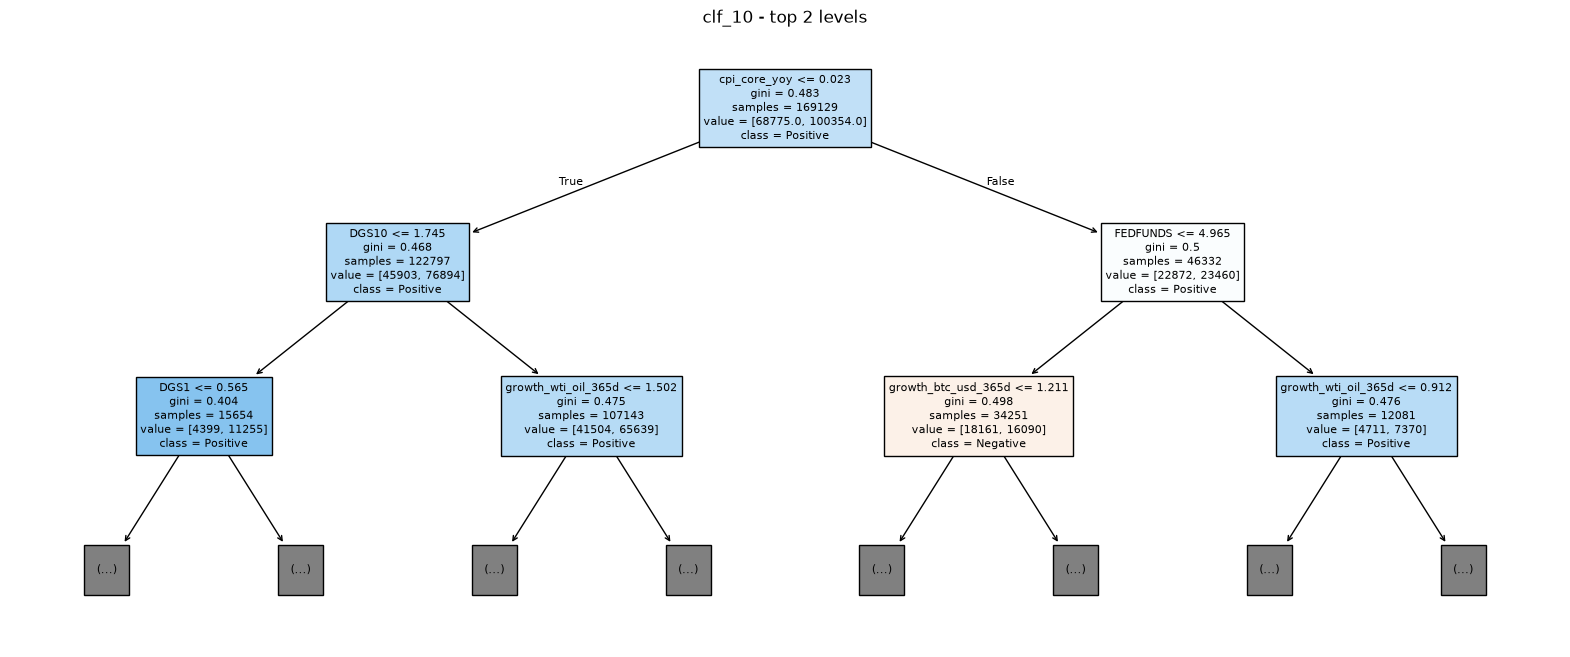

|--- cpi_core_yoy <= 0.02
|   |--- DGS10 <= 1.75
|   |   |--- DGS1 <= 0.56
|   |   |   |--- growth_snp500_90d <= 1.14
|   |   |   |   |--- truncated branch of depth 7
|   |   |   |--- growth_snp500_90d >  1.14
|   |   |   |   |--- truncated branch of depth 7
|   |   |--- DGS1 >  0.56
|   |   |   |--- growth_btc_usd_30d <= 1.07
|   |   |   |   |--- truncated branch of depth 7
|   |   |   |--- growth_btc_usd_30d >  1.07
|   |   |   |   |--- truncated branch of depth 7
|   |--- DGS10 >  1.75
|   |   |--- growth_wti_oil_365d <= 1.50
|   |   |   |--- Month_7 <= 0.50
|   |   |   |   |--- truncated branch of depth 7
|   |   |   |--- Month_7 >  0.50
|   |   |   |   |--- truncated branch of depth 7
|   |   |--- growth_wti_oil_365d >  1.50
|   |   |   |--- growth_wti_oil_30d <= 1.00
|   |   |   |   |--- truncated branch of depth 7
|   |   |   |--- growth_wti_oil_30d >  1.00
|   |   |   |   |--- truncated branch of depth 7
|--- cpi_core_yoy >  0.02
|   |--- FEDFUNDS <= 4.96
|   |   |--- growth_bt

In [11]:
# Visualisation of the top levels of the depth-10 tree (why the branches matter)
plt.figure(figsize=(20, 8))
plot_tree(clf_10, filled=True, feature_names=features_list,
          class_names=['Negative', 'Positive'], max_depth=2)
plt.title('clf_10 - top 2 levels')
plt.show()

# compact textual rules
print(export_text(clf_10, feature_names=list(features_list), max_depth=3))


## Question 4: Hyperparameter tuning (best `max_depth` in 1..12)

In [12]:
precision_by_depth = {}

for max_depth in range(1, 13):
    clf = DecisionTreeClassifier(max_depth=max_depth, random_state=42)
    clf.fit(X_all[train_mask], y_all[train_mask])
    test_precision = precision_score(y_all[test_mask], clf.predict(X_all[test_mask]))
    precision_by_depth[max_depth] = test_precision
    print(f'max_depth = {max_depth:2d} | TEST precision = {test_precision:.4f}')

best_max_depth = max(precision_by_depth, key=precision_by_depth.get)
print()
print('Q4 ANSWER -> best_max_depth =', best_max_depth,
      '| TEST precision =', round(precision_by_depth[best_max_depth], 3))


max_depth =  1 | TEST precision = 0.5701


max_depth =  2 | TEST precision = 0.6225


max_depth =  3 | TEST precision = 0.5720


max_depth =  4 | TEST precision = 0.6292


max_depth =  5 | TEST precision = 0.6000


...

max_depth =  8 | TEST precision = 0.6218


max_depth =  9 | TEST precision = 0.6112


max_depth = 10 | TEST precision = 0.5912


max_depth = 11 | TEST precision = 0.6028


max_depth = 12 | TEST precision = 0.5819

Q4 ANSWER -> best_max_depth = 4 | TEST precision = 0.629


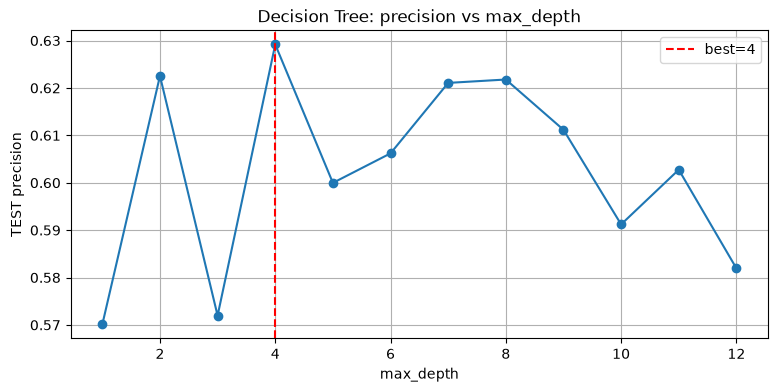

In [13]:
# optional: precision vs depth
plt.figure(figsize=(9, 4))
plt.plot(list(precision_by_depth), list(precision_by_depth.values()), marker='o')
plt.axvline(best_max_depth, color='red', linestyle='--', label=f'best={best_max_depth}')
plt.xlabel('max_depth'); plt.ylabel('TEST precision')
plt.title('Decision Tree: precision vs max_depth')
plt.legend(); plt.grid(True)
plt.show()


In [14]:
# retrain the tuned tree on TRAIN+VALIDATION and predict on the whole dataframe
clf_best = DecisionTreeClassifier(max_depth=best_max_depth, random_state=42)
clf_best.fit(X_all[train_mask], y_all[train_mask])
new_df['pred6_clf_best'] = clf_best.predict(X_all)

print('pred6_clf_best TEST precision:',
      round(precision_score(y_all[test_mask], new_df['pred6_clf_best'][test_mask]), 3))
print('Compare with pred5_clf_10:', round(precision_score(y_all[test_mask], new_df['pred5_clf_10'][test_mask]), 3))


pred6_clf_best TEST precision: 0.629
Compare with pred5_clf_10: 0.591


## Question 5 [EXPLORATORY]: What data is missing?

**Volatility / risk-regime features.** Add the **VIX** (^VIX) and its 30-day change, plus the **yield-curve slope** (e.g. `DGS10 - DGS2` or `T10Y2Y`) and **credit spreads** (BAA10Y). The current macro set only has the level of rates; the *shape* of the curve and market fear drive 30-day forward equity growth. Source: FRED (`DGS2`, `T10Y2Y`, `BAA10Y`, `VIXCLS`) via `pandas_datareader`/`yfinance`.

**Sector / breadth features.** Sector-ETF returns (XLE, XLF, XLK, ...) and market breadth (share of S&P 500 members above their 200-day SMA) capture rotation that single-ticker technicals miss. Source: `yfinance` + S&P 500 constituents list.

**Sentiment / news.** Daily news-sentiment scores or Google-Trends interest per ticker, and **earnings-surprise** magnitude, are leading indicators absent from pure price features. Source: `yfinance` earnings dates, GDELT / news APIs.

**Rationale.** The tree keeps choosing rate levels and October/November seasonality; adding curve slope, VIX and breadth should separate 'calm uptrend' from 'late-cycle' regimes and improve the precision of positive-growth predictions.


## Answers summary

In [15]:
print('=' * 60)
print('Q1  max |corr| (month_wom)              =', Q1_ANSWER)
print('Q2  best NEW hand-rule precision (TEST) =', round(Q2_ANSWER, 3))
print('Q3  unique-correct pred5_clf_10 (TEST)  =', Q3_ANSWER)
print('Q4  best_max_depth                      =', best_max_depth,
      '(precision %.3f)' % precision_by_depth[best_max_depth])
print('=' * 60)


Q1  max |corr| (month_wom)              = 0.025
Q2  best NEW hand-rule precision (TEST) = 0.588
Q3  unique-correct pred5_clf_10 (TEST)  = 1243
Q4  best_max_depth                      = 4 (precision 0.629)
